# Notebook 09: Interpretación de la Red (XAI)

**Objetivo:** Interpretar qué variables financieras utiliza el MLP para predecir la mora, aplicando **permutation importance** sobre el conjunto de Test. La técnica mide cuánto empeora la métrica (ROC-AUC) al permutar aleatoriamente cada variable: mayor caída implica mayor importancia (Sección 15 de la plantilla).

In [1]:
import os
import sys
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# Clonar el repositorio para acceder a la carpeta src (si no existe)
if not os.path.exists('redes-neuronales-riesgo-crediticio'):
    !git clone https://github.com/JuanCardona2203/redes-neuronales-riesgo-crediticio.git

for repo_path in ['/content/redes-neuronales-riesgo-crediticio', '..']:
    if repo_path not in sys.path:
        sys.path.append(repo_path)

from src.model import CreditRiskMLP

In [2]:
# Semilla fija para reproducibilidad (Sección 10)
SEED = 42
np.random.seed(SEED)

# Carga de los datos de Test y del modelo entrenado
X_test_df = pd.read_csv('data/processed/X_test_scaled.csv')
y_test = pd.read_csv('data/processed/y_test.csv').values.ravel()
X_test = X_test_df.values
variables = list(X_test_df.columns)

model = CreditRiskMLP(input_dim=6)
model.load_state_dict(torch.load('models/mlp_credit_risk.pt'))
model.eval()

def predecir_prob(X):
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32)).numpy().ravel()

# ROC-AUC de referencia (sin permutar)
auc_base = roc_auc_score(y_test, predecir_prob(X_test))
print(f'ROC-AUC base: {auc_base:.4f}')

ROC-AUC base: 0.8511


In [3]:
# Permutation importance: se permuta cada variable y se mide la caída de ROC-AUC (Sección 15)
n_repeticiones = 10
importancias = []

for j, nombre in enumerate(variables):
    caidas = []
    for r in range(n_repeticiones):
        rng = np.random.default_rng(SEED + r)
        X_perm = X_test.copy()
        X_perm[:, j] = rng.permutation(X_perm[:, j])
        auc_perm = roc_auc_score(y_test, predecir_prob(X_perm))
        caidas.append(auc_base - auc_perm)
    importancias.append((nombre, np.mean(caidas), np.std(caidas)))

imp_df = pd.DataFrame(importancias, columns=['Variable', 'Importancia', 'Desv'])
imp_df = imp_df.sort_values('Importancia', ascending=False).reset_index(drop=True)
imp_df

,Variable,Importancia,Desv
0,loan_percent_income,0.187120,0.003514
1,loan_int_rate,0.140119,0.003974
2,loan_amnt,0.037159,0.002839
3,person_income,0.015240,0.001452
4,person_age,0.000224,0.000138
5,cb_person_cred_hist_length,0.000090,0.000118


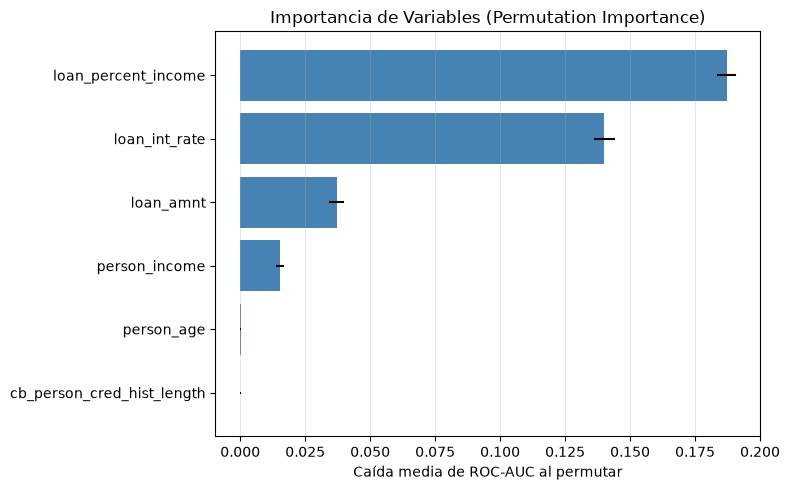

In [4]:
# Gráfica de importancia de variables (Sección 15)
plt.figure(figsize=(8, 5))
plt.barh(imp_df['Variable'], imp_df['Importancia'], xerr=imp_df['Desv'], color='steelblue')
plt.xlabel('Caída media de ROC-AUC al permutar')
plt.title('Importancia de Variables (Permutation Importance)')
plt.gca().invert_yaxis()
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Guardar la importancia de variables como evidencia (Sección 15)
os.makedirs('reports', exist_ok=True)
imp_df.to_csv('reports/importancia_variables.csv', index=False)
print('Variable más influyente:', imp_df.iloc[0]['Variable'])
print('Variable menos influyente:', imp_df.iloc[-1]['Variable'])

Variable más influyente: loan_percent_income
Variable menos influyente: cb_person_cred_hist_length


## Preguntas de interpretación (Sección 15)

| Pregunta | Respuesta |
| :--- | :--- |
| ¿Qué variables o patrones utiliza? | Las variables con mayor caída de ROC-AUC al permutarlas (ver tabla). |
| ¿Dónde falla? | En los falsos negativos (morosos no detectados), según la Sección 14. |
| ¿Qué limita la explicación? | La permutation importance muestra influencia predictiva, **no causalidad**. |
| ¿La explicación demuestra causalidad? | No. Indica correlación con la predicción, no relación causa-efecto. |